# 📚 Library Usage and Book Circulation Analysis
**Student:** Mohd Talish Ansari  |  **Course:** BCA Artificial Intelligence  |  **Semester:** 1st

**Goal:** Analyse library loan data to find the most borrowed books, popular genres, monthly trends, late returns and useful suggestions for the library.

**How to run:** Click *Run All* (VS Code / Jupyter) or *Runtime → Run all* (Google Colab). In Colab, first upload `library_loans_sample.csv` using the 📁 Files panel.

## Step 0: Import the libraries
`pandas` handles tables, `matplotlib` and `seaborn` draw charts, `os` helps with file paths.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")              # clean chart style
plt.rcParams["axes.grid.axis"] = "y"          # only horizontal grid lines

# Colours used in all charts
TEAL, GOLD, BURGUNDY, DARK = "#1F5F5B", "#E0A526", "#8C2F39", "#1E2B2A"
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Load and inspect the data

In [2]:
# Find the CSV file (works in VS Code and in Google Colab)
possible_paths = [
    "../dataset/library_loans_sample.csv",    # VS Code / Jupyter (notebook is inside notebooks/)
    "dataset/library_loans_sample.csv",       # if you open the project root
    "library_loans_sample.csv",               # Google Colab (file uploaded to the main folder)
]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Upload library_loans_sample.csv (see README) and run again.")

df = pd.read_csv(DATA_PATH)                   # read CSV into a DataFrame (table)
print("Loaded from:", DATA_PATH)
print("Rows, Columns:", df.shape)
df.head()

Loaded from: ../dataset/library_loans_sample.csv
Rows, Columns: (900, 10)


,Loan_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Issue_Date,Due_Date,Return_Date,Loan_Status
0,L0001,M0021,B019,Harry Potter and the Philosopher's Stone,J. K. Rowling,Science Fiction & Fantasy,2025-01-01,2025-01-15,2025-01-10,Returned
1,L0002,M0053,B002,Introduction to Algorithms,Thomas H. Cormen,Computer Science & AI,2025-01-02,2025-01-16,2025-01-10,Returned
2,L0003,M0180,B043,Wings of Fire,A. P. J. Abdul Kalam,History & Biography,2025-01-02,2025-01-16,2025-01-23,Returned
3,L0004,M0123,B007,The Alchemist,Paulo Coelho,Fiction,2025-01-02,2025-01-16,2025-01-04,Returned
4,L0005,M0133,B015,Objective General English,S. P. Bakshi,Competitive Exams & Study Guides,2025-01-03,2025-01-17,2025-01-10,Returned


In [3]:
# Column names, data types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Loan_ID      900 non-null    str  
 1   Member_ID    900 non-null    str  
 2   Book_ID      900 non-null    str  
 3   Book_Title   900 non-null    str  
 4   Author       900 non-null    str  
 5   Genre        900 non-null    str  
 6   Issue_Date   900 non-null    str  
 7   Due_Date     900 non-null    str  
 8   Return_Date  870 non-null    str  
 9   Loan_Status  900 non-null    str  
dtypes: str(10)
memory usage: 70.4 KB

Missing values per column:
Loan_ID         0
Member_ID       0
Book_ID         0
Book_Title      0
Author          0
Genre           0
Issue_Date      0
Due_Date        0
Return_Date    30
Loan_Status     0
dtype: int64


**Note:** `Return_Date` is blank for the books that are still with members. This is normal, not an error.

## Step 2: Clean and preprocess the data

In [4]:
# 2.1 Remove extra spaces in text columns
text_cols = ["Member_ID", "Book_ID", "Book_Title", "Author", "Genre", "Loan_Status"]
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

# 2.2 Remove duplicate loans
before = len(df)
df = df.drop_duplicates(subset="Loan_ID")
print("Duplicates removed:", before - len(df))

# 2.3 Convert date columns from text to real dates
for col in ["Issue_Date", "Due_Date", "Return_Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# 2.4 Check: a book cannot be returned before it was issued
print("Invalid rows (returned before issue):", (df["Return_Date"] < df["Issue_Date"]).sum())
df = df[~(df["Return_Date"] < df["Issue_Date"])]

Duplicates removed: 0
Invalid rows (returned before issue): 0


In [5]:
# 2.5 Create new helpful columns
df["Issue_Month"] = df["Issue_Date"].dt.to_period("M").astype(str)     # e.g. 2025-09
df["Issue_Weekday"] = df["Issue_Date"].dt.day_name()                   # e.g. Monday
df["Days_Borrowed"] = (df["Return_Date"] - df["Issue_Date"]).dt.days   # how long the book was kept
df["Days_Late"] = (df["Return_Date"] - df["Due_Date"]).dt.days.clip(lower=0)

# On-time / Late / Not returned yet
df["Return_Type"] = "Not Returned Yet"
returned = df["Return_Date"].notna()
df.loc[returned & (df["Return_Date"] <= df["Due_Date"]), "Return_Type"] = "On-time"
df.loc[returned & (df["Return_Date"] > df["Due_Date"]), "Return_Type"] = "Late"

print("Clean dataset shape:", df.shape)
df[["Loan_ID", "Book_Title", "Issue_Date", "Due_Date", "Return_Date", "Loan_Status", "Days_Late", "Return_Type"]].head()

Clean dataset shape: (900, 15)


,Loan_ID,Book_Title,Issue_Date,Due_Date,Return_Date,Loan_Status,Days_Late,Return_Type
0,L0001,Harry Potter and the Philosopher's Stone,2025-01-01,2025-01-15,2025-01-10,Returned,0.0,On-time
1,L0002,Introduction to Algorithms,2025-01-02,2025-01-16,2025-01-10,Returned,0.0,On-time
2,L0003,Wings of Fire,2025-01-02,2025-01-16,2025-01-23,Returned,7.0,Late
3,L0004,The Alchemist,2025-01-02,2025-01-16,2025-01-04,Returned,0.0,On-time
4,L0005,Objective General English,2025-01-03,2025-01-17,2025-01-10,Returned,0.0,On-time


## Step 3: Total books borrowed

In [6]:
print("Total books issued (loans):", len(df))
print("Unique books borrowed     :", df["Book_ID"].nunique())
print("Unique members            :", df["Member_ID"].nunique())

Total books issued (loans): 900
Unique books borrowed     : 60
Unique members            : 169


## Step 4: Most borrowed books (Top 10)

In [7]:
# Count how many times each book was borrowed, then take the 10 highest
top = (df.groupby(["Book_Title", "Genre"]).size().reset_index(name="Times_Borrowed")
         .sort_values(["Times_Borrowed", "Book_Title"], ascending=[False, True])
         .head(10).reset_index(drop=True))
top.index = top.index + 1          # ranks start from 1
top

,Book_Title,Genre,Times_Borrowed
1,Python Crash Course,Computer Science & AI,56
2,Introduction to Algorithms,Computer Science & AI,48
3,The Alchemist,Fiction,46
4,Artificial Intelligence: A Modern Approach,Computer Science & AI,27
5,Quantitative Aptitude,Competitive Exams & Study Guides,27
6,To Kill a Mockingbird,Fiction,26
7,Clean Code,Computer Science & AI,25
8,Indian Polity,Competitive Exams & Study Guides,25
9,Atomic Habits,Self-Help & Motivation,24
10,Objective General English,Competitive Exams & Study Guides,24


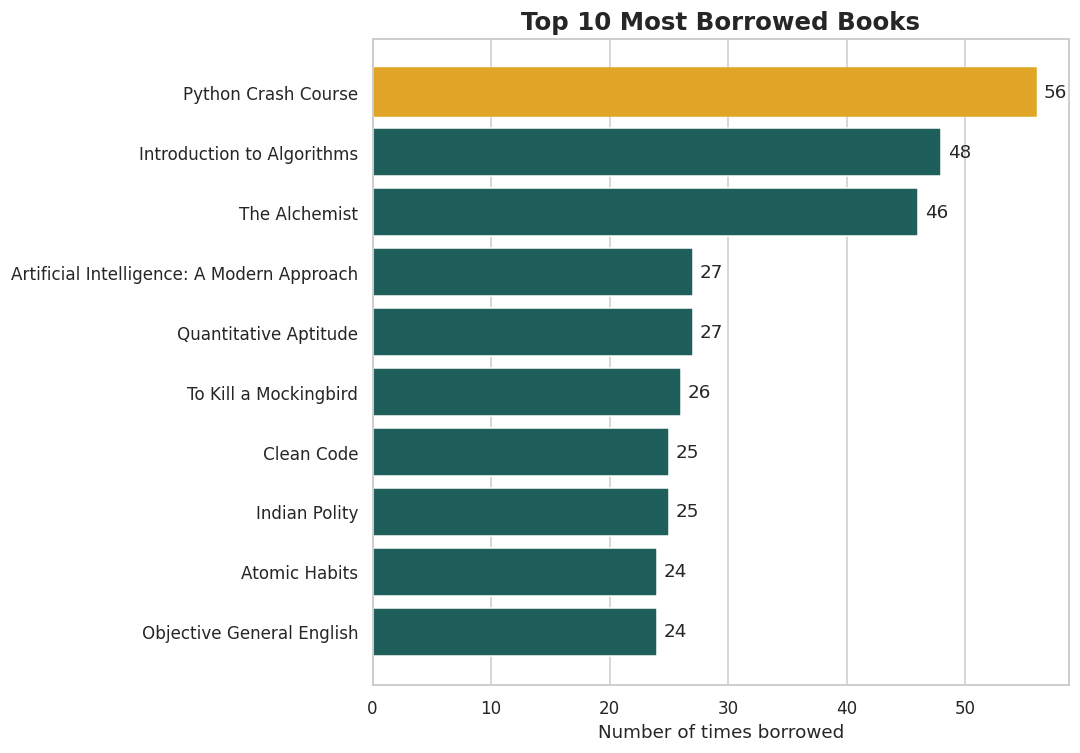

In [8]:
# Chart 1: Bar chart - Top 10 borrowed books
fig, ax = plt.subplots(figsize=(10, 7))
t = top.iloc[::-1]                                         # reverse so rank 1 is at the top
bars = ax.barh(t["Book_Title"], t["Times_Borrowed"], color=TEAL)
bars[-1].set_color(GOLD)                                   # highlight the most borrowed book
for b in bars:
    ax.text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2, int(b.get_width()), va="center")
ax.set_title("Top 10 Most Borrowed Books", fontsize=16, fontweight="bold")
ax.set_xlabel("Number of times borrowed")
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
plt.tight_layout()
plt.show()

## Step 5: Most popular genres

In [9]:
genre = df["Genre"].value_counts()
genre_table = pd.DataFrame({"Loans": genre, "Percent": (genre / genre.sum() * 100).round(1)})
genre_table

,Loans,Percent
Genre,,
Computer Science & AI,187,20.8
Fiction,128,14.2
Competitive Exams & Study Guides,116,12.9
Science Fiction & Fantasy,85,9.4
Self-Help & Motivation,78,8.7
Mystery & Thriller,73,8.1
History & Biography,69,7.7
Science & Mathematics,58,6.4
Business & Economics,55,6.1


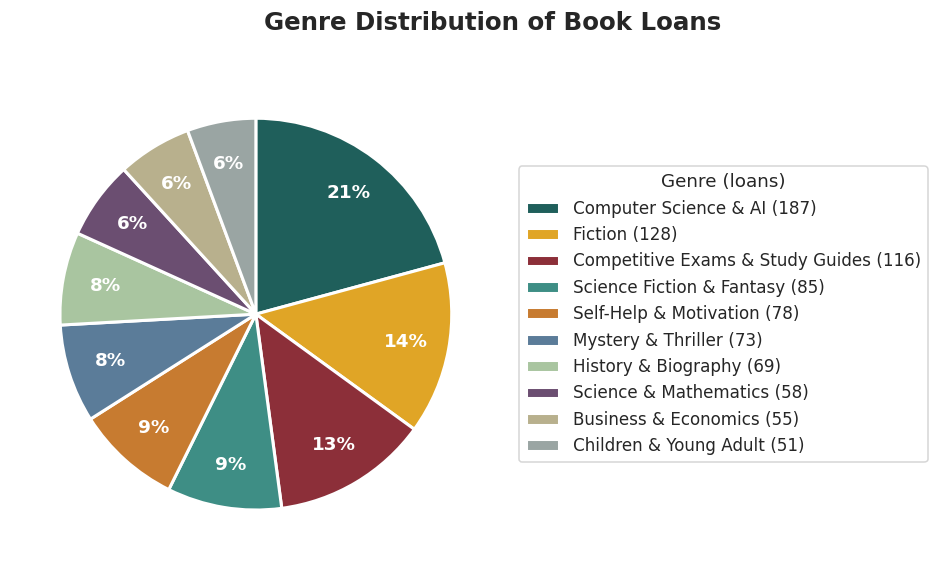

In [10]:
# Chart 2: Pie chart - Genre distribution
colors = ["#1F5F5B", "#E0A526", "#8C2F39", "#3E8E85", "#C77B30",
          "#5B7C99", "#A9C5A0", "#6B4E71", "#B8B08D", "#9AA5A3"]
fig, ax = plt.subplots(figsize=(10, 5.3))
wedges, _, autotexts = ax.pie(genre.values, colors=colors, startangle=90, counterclock=False,
                              autopct=lambda p: f"{p:.0f}%" if p >= 5 else "",
                              pctdistance=0.78, wedgeprops=dict(edgecolor="white", linewidth=2))
for a in autotexts:
    a.set_color("white"); a.set_fontweight("bold")
ax.legend(wedges, [f"{g} ({v})" for g, v in zip(genre.index, genre.values)],
          title="Genre (loans)", loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.suptitle("Genre Distribution of Book Loans", fontsize=16, fontweight="bold")
fig.subplots_adjust(left=0.02, right=0.55, top=0.88, bottom=0.04)
plt.show()

## Step 6: Monthly circulation analysis

In [11]:
monthly = df.groupby("Issue_Month").size()                       # loans per month
monthly.index = pd.to_datetime(monthly.index + "-01").strftime("%b")   # 2025-09 -> Sep
print(monthly)
print("\nBusiest month :", monthly.idxmax(), "-", monthly.max(), "loans")
print("Quietest month:", monthly.idxmin(), "-", monthly.min(), "loans")

Issue_Month
Jan     60
Feb     70
Mar     82
Apr     65
May     59
Jun     56
Jul     70
Aug    102
Sep    116
Oct    100
Nov     72
Dec     48
dtype: int64

Busiest month : Sep - 116 loans
Quietest month: Dec - 48 loans


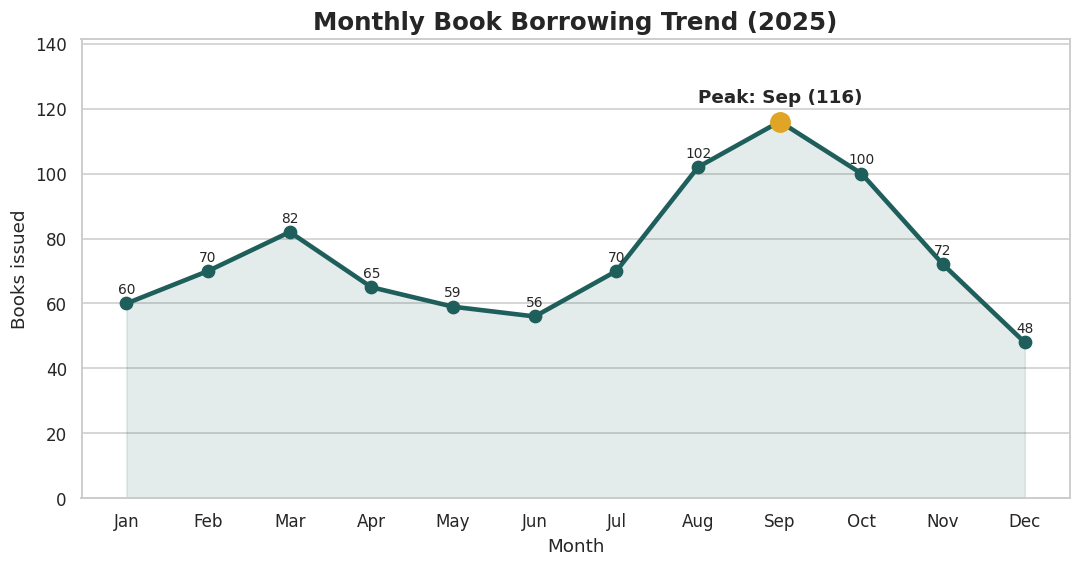

In [12]:
# Chart 3: Line chart - Monthly borrowing trend
fig, ax = plt.subplots(figsize=(10, 5.3))
ax.plot(monthly.index, monthly.values, marker="o", markersize=8, linewidth=3, color=TEAL)
ax.fill_between(range(len(monthly)), monthly.values, alpha=0.12, color=TEAL)
peak = monthly.idxmax()
ax.scatter([peak], [monthly.max()], s=160, color=GOLD, zorder=5)
for x, y in zip(monthly.index, monthly.values):
    if x == peak:
        ax.text(x, y + 6, f"Peak: {x} ({y})", ha="center", fontweight="bold")
    else:
        ax.text(x, y + 3, str(y), ha="center", fontsize=9)
ax.set_title("Monthly Book Borrowing Trend (2025)", fontsize=16, fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Books issued")
ax.set_ylim(0, monthly.max() * 1.22)
plt.tight_layout()
plt.show()

In [13]:
# Library usage pattern: which weekday is busiest?
weekday = df["Issue_Weekday"].value_counts()
weekday

Issue_Weekday
Friday       168
Thursday     156
Monday       151
Wednesday    148
Tuesday      147
Saturday     130
Name: count, dtype: int64

## Step 7: Returned vs currently borrowed books

In [14]:
status = df["Loan_Status"].value_counts().reindex(["Returned", "Issued", "Overdue"]).fillna(0).astype(int)
print(status)
print("\nCurrently borrowed (Issued + Overdue):", status["Issued"] + status["Overdue"])

Loan_Status
Returned    870
Issued       22
Overdue       8
Name: count, dtype: int64

Currently borrowed (Issued + Overdue): 30


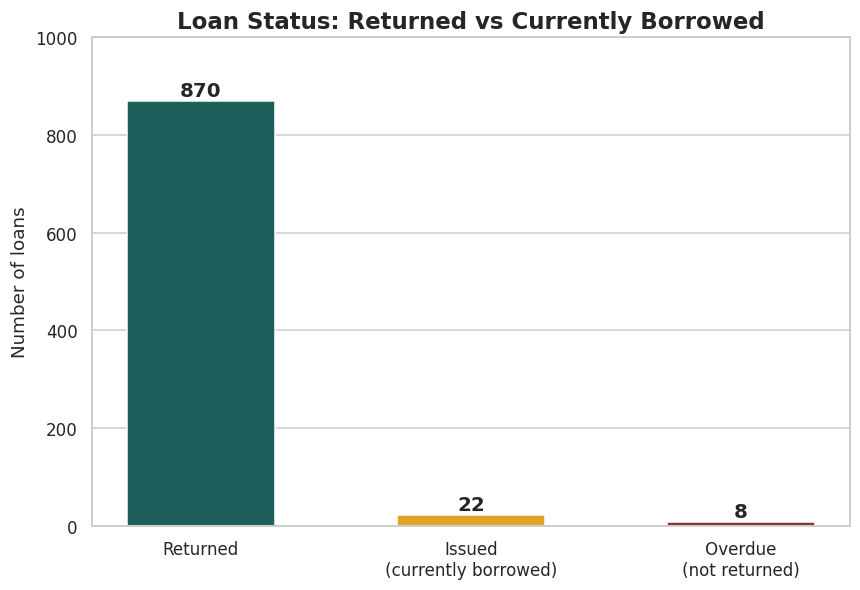

In [15]:
# Chart 4: Bar chart - Returned vs currently borrowed
fig, ax = plt.subplots(figsize=(8, 5.5))
labels = ["Returned", "Issued\n(currently borrowed)", "Overdue\n(not returned)"]
bars = ax.bar(labels, status.values, color=[TEAL, GOLD, BURGUNDY], width=0.55)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 10, int(b.get_height()),
            ha="center", fontsize=13, fontweight="bold")
ax.set_title("Loan Status: Returned vs Currently Borrowed", fontsize=15, fontweight="bold")
ax.set_ylabel("Number of loans")
ax.set_ylim(0, status.max() * 1.15)
plt.tight_layout()
plt.show()

## Step 8: Late-return analysis
A book is **late** when `Return_Date` is after `Due_Date`. We only judge books that have been returned.

In [16]:
returned_df = df[df["Loan_Status"] == "Returned"]
counts = returned_df["Return_Type"].value_counts().reindex(["On-time", "Late"]).fillna(0).astype(int)
late_pct = counts["Late"] / counts.sum() * 100
late_only = returned_df[returned_df["Return_Type"] == "Late"]

print(counts)
print(f"\nLate-return rate  : {late_pct:.1f}%")
print(f"Average days late : {late_only['Days_Late'].mean():.1f}")
print(f"Maximum days late : {int(late_only['Days_Late'].max())}")

# Late-return rate for each genre
late_by_genre = (returned_df.groupby("Genre")["Return_Type"]
                 .apply(lambda s: (s == "Late").mean() * 100).round(1)
                 .sort_values(ascending=False))
print("\nLate-return rate by genre (%):")
print(late_by_genre)

Return_Type
On-time    631
Late       239
Name: count, dtype: int64

Late-return rate  : 27.5%
Average days late : 6.3
Maximum days late : 21

Late-return rate by genre (%):
Genre
History & Biography                 43.3
Children & Young Adult              40.4
Mystery & Thriller                  35.2
Fiction                             27.4
Science & Mathematics               25.5
Competitive Exams & Study Guides    25.4
Business & Economics                23.1
Science Fiction & Fantasy           22.9
Computer Science & AI               22.8
Self-Help & Motivation              22.1
Name: Return_Type, dtype: float64


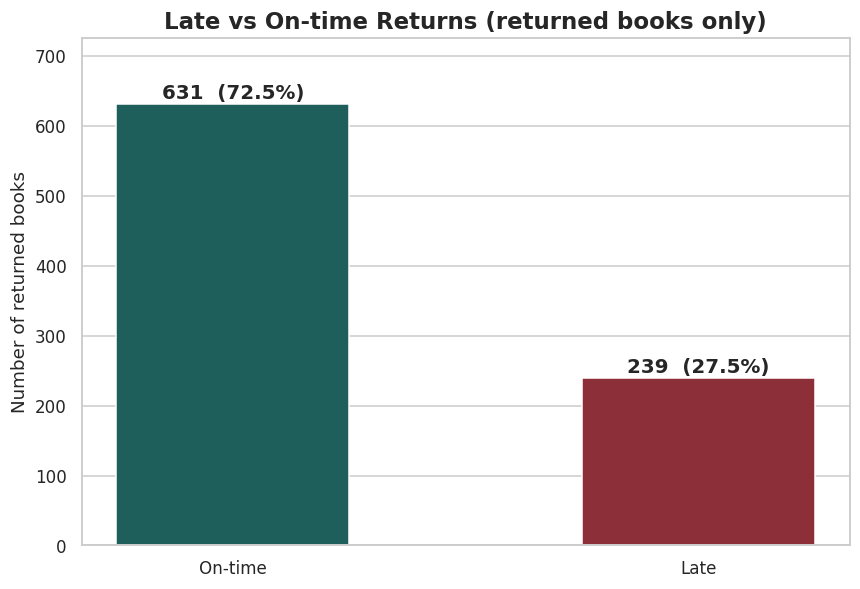

In [17]:
# Chart 5: Bar chart - Late vs on-time returns
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(["On-time", "Late"], counts.values, color=[TEAL, BURGUNDY], width=0.5)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 8,
            f"{int(b.get_height())}  ({b.get_height() / counts.sum() * 100:.1f}%)",
            ha="center", fontsize=13, fontweight="bold")
ax.set_title("Late vs On-time Returns (returned books only)", fontsize=15, fontweight="bold")
ax.set_ylabel("Number of returned books")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

## Step 9: Key Performance Indicators (KPIs)

In [18]:
kpis = {
    "Total Loans": len(df),
    "Unique Books Borrowed": df["Book_ID"].nunique(),
    "Active Members": df["Member_ID"].nunique(),
    "Books Returned": int(status["Returned"]),
    "Currently Borrowed": int(status["Issued"] + status["Overdue"]),
    "Overdue (Not Returned)": int(status["Overdue"]),
    "Return Rate (%)": round(status["Returned"] / len(df) * 100, 1),
    "Late-Return Rate (%)": round(late_pct, 1),
    "Avg Days Borrowed": round(returned_df["Days_Borrowed"].mean(), 1),
    "Avg Days Late (late books)": round(late_only["Days_Late"].mean(), 1),
    "Most Popular Genre": genre.idxmax(),
    "Busiest Month": monthly.idxmax(),
}
pd.DataFrame(list(kpis.items()), columns=["KPI", "Value"])

,KPI,Value
0,Total Loans,900
1,Unique Books Borrowed,60
2,Active Members,169
3,Books Returned,870
4,Currently Borrowed,30
5,Overdue (Not Returned),8
6,Return Rate (%),96.7
7,Late-Return Rate (%),27.5
8,Avg Days Borrowed,11.7
9,Avg Days Late (late books),6.3


## Step 10: Final business insights and recommendations

In [19]:
print("KEY INSIGHTS")
print(f"1. '{top.loc[1, 'Book_Title']}' is the most borrowed book ({top.loc[1, 'Times_Borrowed']} loans).")
print(f"2. {genre.idxmax()} is the most popular genre ({genre.max() / genre.sum() * 100:.1f}% of loans); "
      f"the top 3 genres give {genre.head(3).sum() / genre.sum() * 100:.1f}%.")
print(f"3. {monthly.idxmax()} is the busiest month ({monthly.max()} loans); {monthly.idxmin()} is the quietest ({monthly.min()}).")
print(f"4. {late_pct:.1f}% of returned books were late (average {late_only['Days_Late'].mean():.1f} days late).")
print(f"5. {kpis['Currently Borrowed']} books are currently borrowed; {kpis['Overdue (Not Returned)']} are already overdue.")
print(f"6. {weekday.idxmax()} is the busiest weekday.")
print(f"7. '{late_by_genre.index[0]}' has the highest late-return rate ({late_by_genre.iloc[0]}%).")

print("\nRECOMMENDATIONS")
print("1. Buy more copies of high-demand titles and top genres so students do not wait.")
print(f"2. Prepare extra stock and staff before busy months such as {monthly.idxmax()}.")
print("3. Send SMS/e-mail reminders 2 days before the due date to reduce late returns.")
print("4. Add a small fine or borrowing limit for repeat late members.")
print("5. Follow up with members who still hold overdue books.")
print("6. Run reading campaigns in quiet months to keep usage steady.")

KEY INSIGHTS
1. 'Python Crash Course' is the most borrowed book (56 loans).
2. Computer Science & AI is the most popular genre (20.8% of loans); the top 3 genres give 47.9%.
3. Sep is the busiest month (116 loans); Dec is the quietest (48).
4. 27.5% of returned books were late (average 6.3 days late).
5. 30 books are currently borrowed; 8 are already overdue.
6. Friday is the busiest weekday.
7. 'History & Biography' has the highest late-return rate (43.3%).

RECOMMENDATIONS
1. Buy more copies of high-demand titles and top genres so students do not wait.
2. Prepare extra stock and staff before busy months such as Sep.
3. Send SMS/e-mail reminders 2 days before the due date to reduce late returns.
4. Add a small fine or borrowing limit for repeat late members.
5. Follow up with members who still hold overdue books.
6. Run reading campaigns in quiet months to keep usage steady.


## ✅ Conclusion
The analysis shows that the library is mostly used for **academic books (Computer Science, competitive exams)**, usage **peaks at the start of the semester**, and about **1 in 4 books is returned late**. Using these results the library can plan better purchases, send reminders and improve service.